# Визначення часу проведення експерименту

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

mean_sets=pd.read_csv("wait_times_mean.csv",index_col=0)
mean_sets.head()

,Run_0,Run_1,Run_2,Run_3
Time_Step,,,,
100.0,22.519769,17.753014,20.042334,17.664171
200.0,25.838888,24.194444,25.575886,19.365937
300.0,24.187783,23.153904,24.931196,25.460570
400.0,25.112665,25.513621,25.960726,26.866460
500.0,26.358978,24.631492,26.058862,28.711359


Функція визначення останнього індексу, на якому різниця між максимальним і мінімальним значенням моделі менша за певний поріг

In [2]:
def threshold(dataframe):
    fraction=0.05

    df=dataframe
    mean_curve = df.mean(axis=1)
    max_curve = df.max(axis=1)
    min_curve = df.min(axis=1)

    # Find last index where error exceeds (or 1% relative error)
    unstable = df[(max_curve - min_curve).abs() > mean_curve*fraction].index
    t_steady = unstable[-1] if not unstable.empty else 0
    print(f"Steady-state threshold T_model = {t_steady}")

Зчитування файлів:

In [3]:
df_mean_store=pd.read_csv("wait_times_mean.csv",index_col=0)
df_std_store=pd.read_csv("wait_times_std.csv",index_col=0)
df_small_load=3.-pd.read_csv("small_planes_load.csv",index_col=0)
df_big_load=2.-pd.read_csv("big_planes_load.csv",index_col=0)

Визначення порогу

In [4]:
print("Threshold for average storage wait time:")
threshold(df_mean_store)
print("\nThreshold for std storage wait time:")
threshold(df_std_store)
print("\nThreshold for average small plane load:")
threshold(df_small_load)
print("\nThreshold for average big plane load:")
threshold(df_big_load)

Threshold for average storage wait time:
Steady-state threshold T_model = 5200.0

Threshold for std storage wait time:
Steady-state threshold T_model = 3900.0

Threshold for average small plane load:
Steady-state threshold T_model = 5200.0

Threshold for average big plane load:
Steady-state threshold T_model = 85200.0


Зображення графіків відгуку моделі залежно від часу

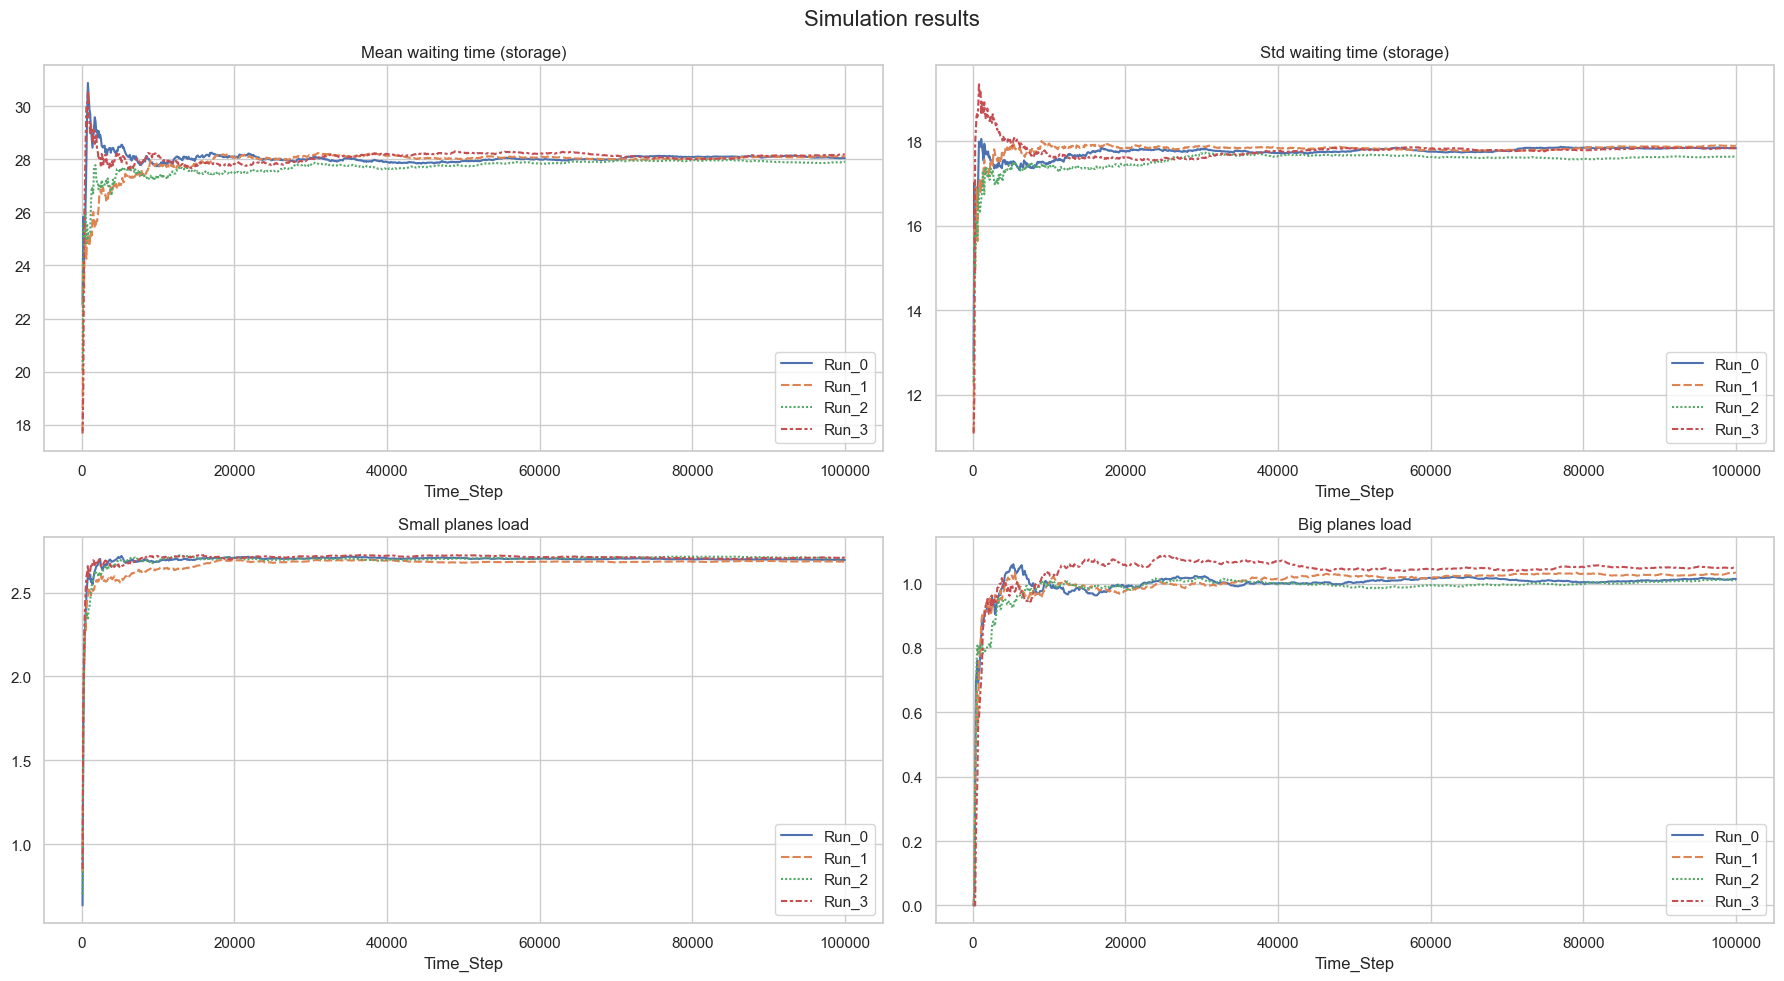

In [5]:
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(2, 2, figsize=(18, 10))

sns.lineplot(data=df_mean_store, ax=axes[0, 0])
axes[0, 0].set_title("Mean waiting time (storage)")

sns.lineplot(data=df_std_store, ax=axes[0, 1])
axes[0, 1].set_title("Std waiting time (storage)")


sns.lineplot(data=df_small_load, ax=axes[1, 0])
axes[1, 0].set_title("Small planes load")

sns.lineplot(data=df_big_load, ax=axes[1, 1])
axes[1, 1].set_title("Big planes load")

fig.suptitle("Simulation results", fontsize=16)

plt.tight_layout()
plt.show()

# Визначення розподілу часу очікування всередині одного запуску

Час очікування контейнеру перед початком завантаження

<Axes: ylabel='Count'>

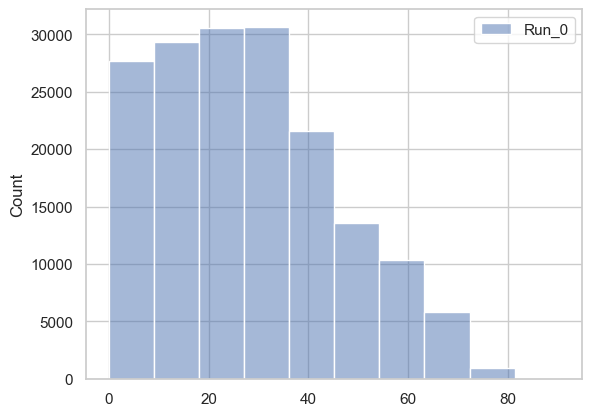

In [6]:
df=pd.read_csv("single_store_wait_time.csv")
sns.histplot(df, bins=10)

## Тести Хі-квадрату

Параметри розподілу Ерланга: k=2, loc=-5.218246557282553, scale=10.716814823638806
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 115008.82632904215, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=28.316090985909845, std=17.72179625836713
Подібність розподілу Нормального: dof: 9, chi2_stat: 6636.550082159569, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=28.316090985909845
Chi-squared test (Exponential): dof: 9, chi2_stat: 38791.99983449818, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.9880485671199365, loc=0, scale=20.70197094216915
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 45320.17032544799, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу
 

Усічений нормальний розподіл:
  loc=28.3161, scale=17.7218, low=0.0, high=90.33392655122589
Chi-squared test 

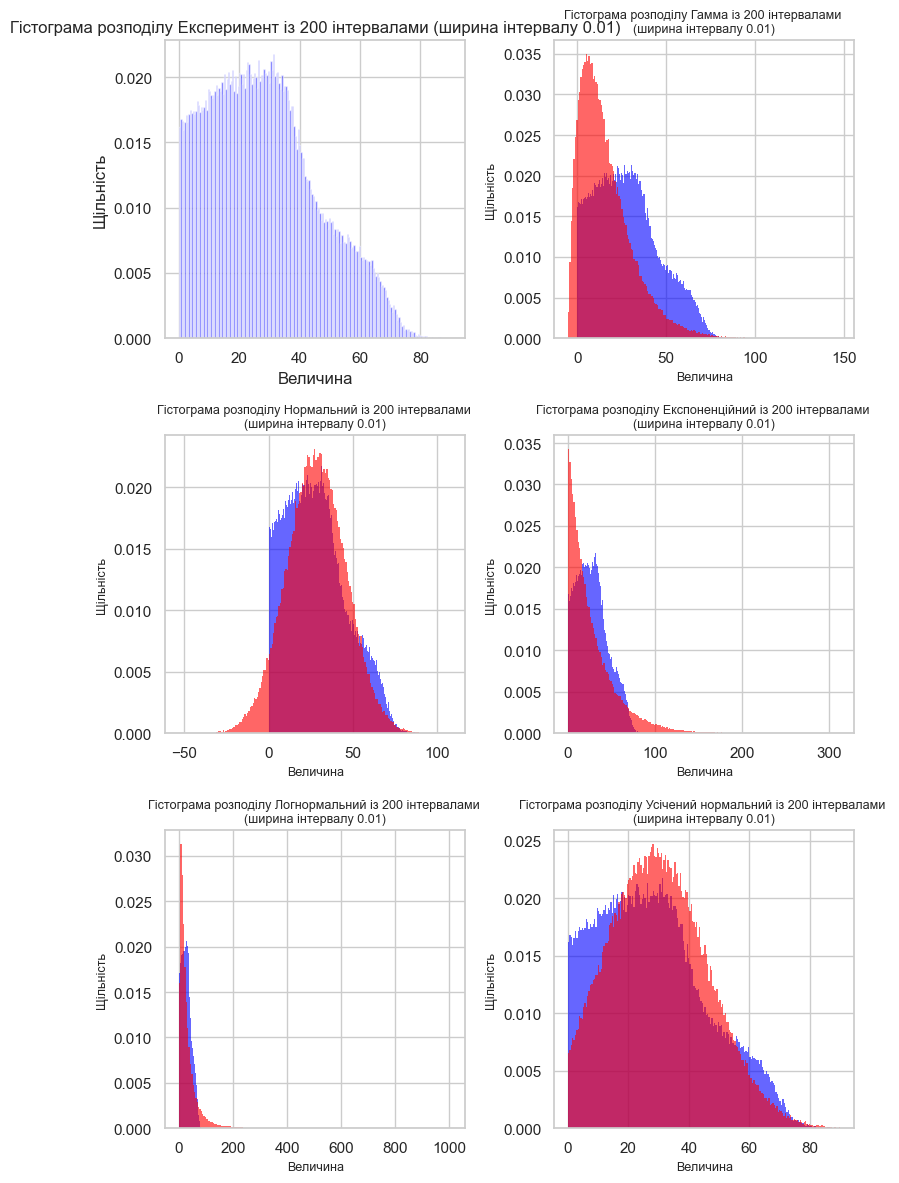

In [7]:
df=pd.read_csv("single_store_wait_time.csv")
df=df[df>0].dropna()
from Distributions import distribution_analysis
distribution_analysis(df.iloc[:,0])

In [8]:
import sys
import importlib
importlib.reload(sys.modules['Distributions'])
import numpy as np
df=pd.read_csv("single_store_wait_time.csv")
df=pd.DataFrame.to_numpy(df)
df=df.flatten()

df=df[~np.isnan(df)]
df=df[df>0]
df_1=np.random.choice(df,5000)
df_2=np.random.choice(df,5000)
import Distributions
Distributions.chi_squared_check(df_1,Distributions.make_empirical_cdf(df_2))

'dof: 9, chi2_stat: 19.660000000017746, chi2_treshold: 16.918977604620448\n0.020130599213147467<0.05: відхиляємо гіпотезу\n'

Параметри розподілу Ерланга: k=2, loc=-4.161423707638512, scale=11.309623862056174
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 87.10000000000115, chi2_treshold: 16.918977604620448
6.205489382570726e-15<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=28.046808697914862, std=17.696993627054564
Подібність розподілу Нормального: dof: 9, chi2_stat: 17.900000000001086, chi2_treshold: 16.918977604620448
0.03635160173412094<0.05: відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=28.046808697914862
Chi-squared test (Exponential): dof: 9, chi2_stat: 48.29999999999999, chi2_treshold: 16.918977604620448
2.2446143962881796e-07<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.9811007072348489, loc=0, scale=20.484578008083577
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 55.70000000000044, chi2_treshold: 16.918977604620448
8.956159919317144e-09<0.05: відхиляємо гіпотезу
 

Усічений нормальний розподіл:
  loc=

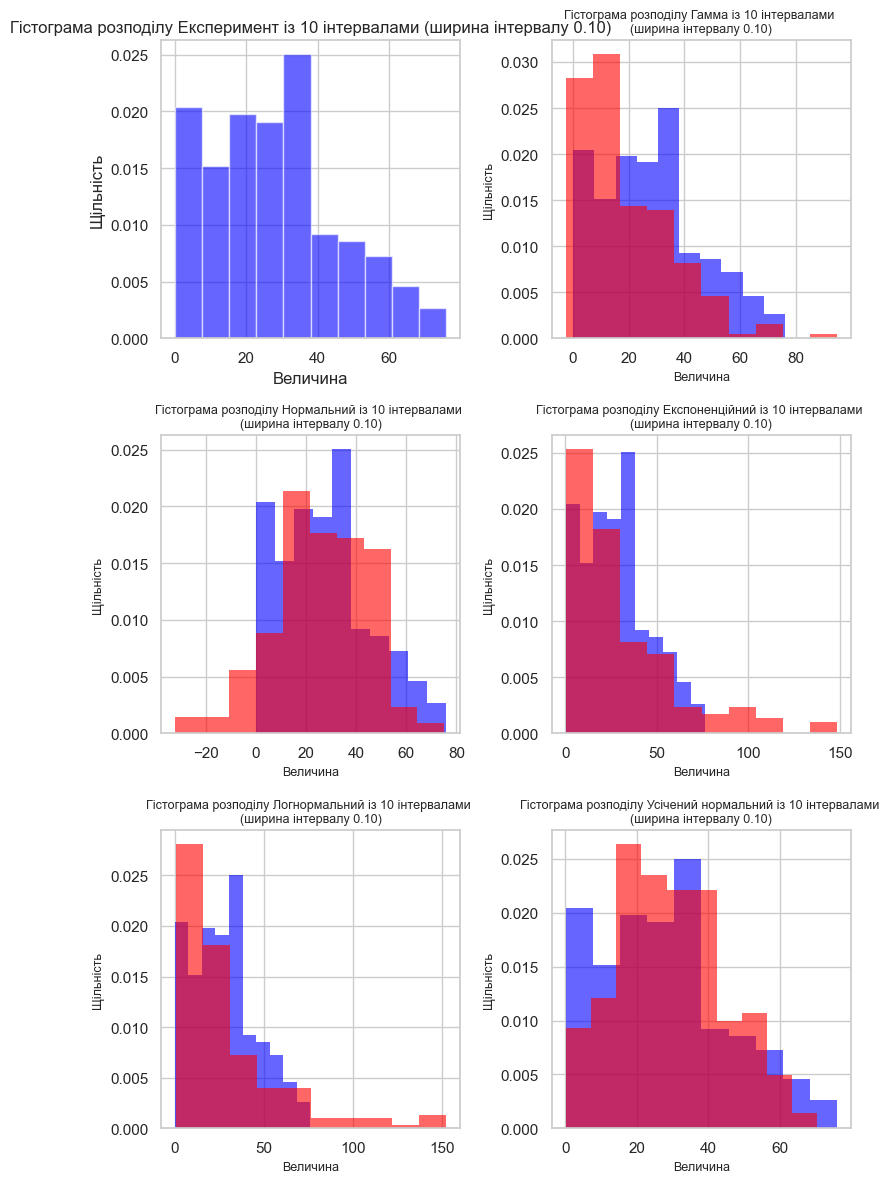

In [9]:
import numpy as np
df=pd.read_csv("single_store_wait_time.csv")
df=pd.DataFrame.to_numpy(df)
df=df.flatten()
df=df[~np.isnan(df)]
df=df[df>0]
df=np.random.choice(df,200)
from Distributions import distribution_analysis
distribution_analysis(df,10)

Параметри розподілу Ерланга: k=2, loc=-1.8513300900293328, scale=14.326262637435454
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 20.849999999999977, chi2_treshold: 16.918977604620448
0.013333352564549936<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=28.35837701163158, std=18.520005824485843
Подібність розподілу Нормального: dof: 9, chi2_stat: 23.700000000000646, chi2_treshold: 16.918977604620448
0.004801671146983376<0.05: відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=28.35837701163158
Chi-squared test (Exponential): dof: 9, chi2_stat: 77.05000000000227, chi2_treshold: 16.918977604620448
6.215242255704844e-13<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=1.0003658427526119, loc=0, scale=20.247366205072822
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 108.6000000000011, chi2_treshold: 16.918977604620448
2.8335804215593667e-19<0.05: відхиляємо гіпотезу
 

Усічений нормальний розподіл:
  loc=

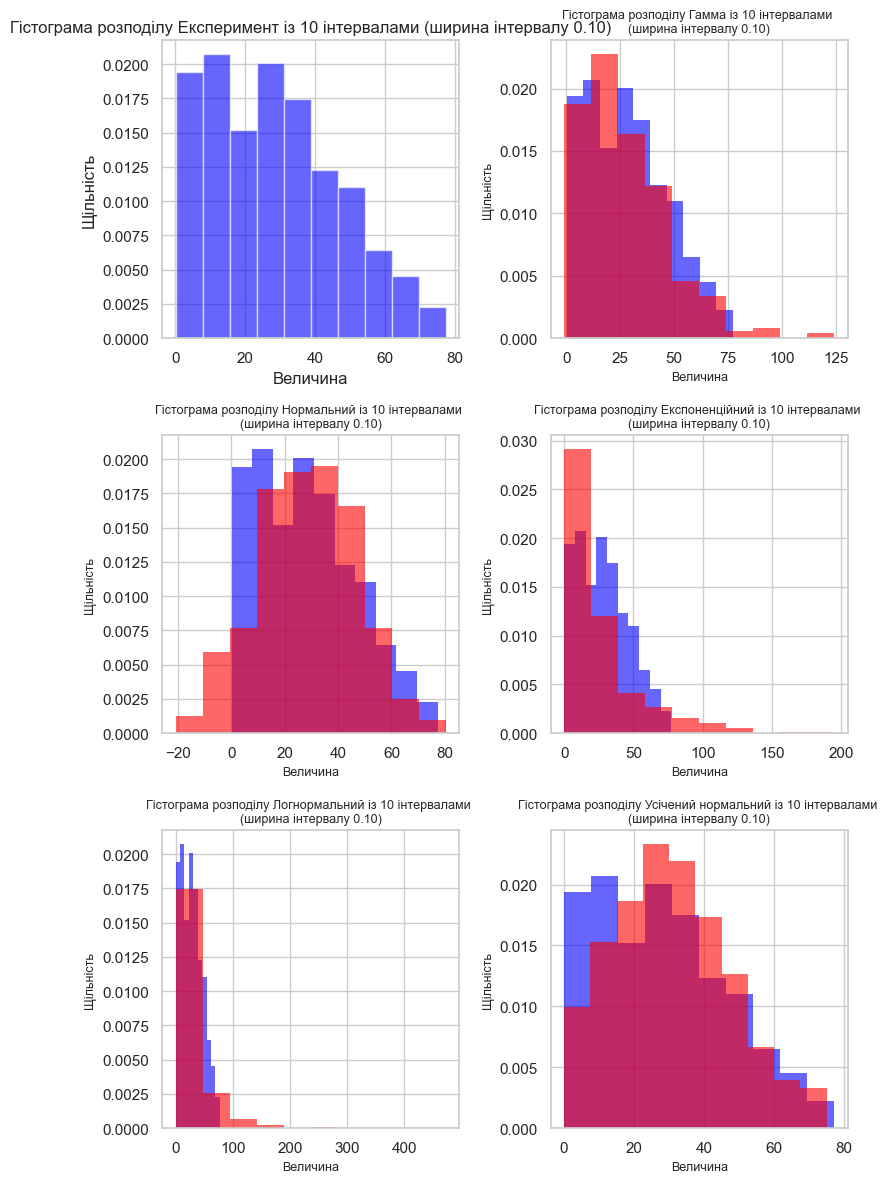

In [10]:
import numpy as np
df=pd.read_csv("80_store_wait_time.csv")
df=pd.DataFrame.to_numpy(df)
df=df.flatten()
df=df[~np.isnan(df)]
df=df[df>0]
df=np.random.choice(df,400)
from Distributions import distribution_analysis
distribution_analysis(df,10)

# Визначення середнього відгуку моделі

In [11]:
df=pd.read_csv("80_parametre_runs.csv")
df.head()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
0,Run_0,85300.0,3,2,0.5,0.0,27.99,2.699,1.038,56.0,170240.0
1,Run_1,85300.0,3,2,0.5,0.0,28.03,2.696,1.062,56.0,170100.0
2,Run_2,85300.0,3,2,0.5,0.0,28.06,2.698,1.022,56.3,170720.0
3,Run_3,85300.0,3,2,0.5,0.0,27.97,2.701,1.010,56.1,170700.0
4,Run_4,85300.0,3,2,0.5,0.0,27.97,2.664,1.047,55.9,169880.0


In [12]:
df=df[["AvgStoreWait","SmallUtil","BigUtil"]]
df.describe()

,AvgStoreWait,SmallUtil,BigUtil
count,80.000000,80.000000,80.000000
mean,28.051375,2.694850,1.029512
std,0.142240,0.010823,0.016167
min,27.720000,2.664000,0.984000
25%,27.960000,2.688750,1.019250
50%,28.045000,2.696000,1.031000
75%,28.140000,2.701250,1.041000
max,28.460000,2.724000,1.062000


Визначення типу розподілу середнього часу очікування в аеропорті

Параметри розподілу Ерланга: k=2, loc=27.27430079076294, scale=0.025653558270082887
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 719.9999999993616, chi2_treshold: 16.918977604620448
3.464432377743967e-149<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=28.051374999999997, std=0.14134836176977805
Подібність розподілу Нормального: dof: 9, chi2_stat: 5.999999999969727, chi2_treshold: 16.918977604620448
0.7399182920976834>=0.05: не відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=28.051374999999997
Chi-squared test (Exponential): dof: 9, chi2_stat: 719.9999999999745, chi2_treshold: 16.918977604620448
3.464432376692533e-149<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.005033989779421473, loc=0, scale=28.051019346686815
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 5.999999999938263, chi2_treshold: 16.918977604620448
0.7399182921008327>=0.05: не відхиляємо гіпотезу
 

Усічений нормальний розподіл

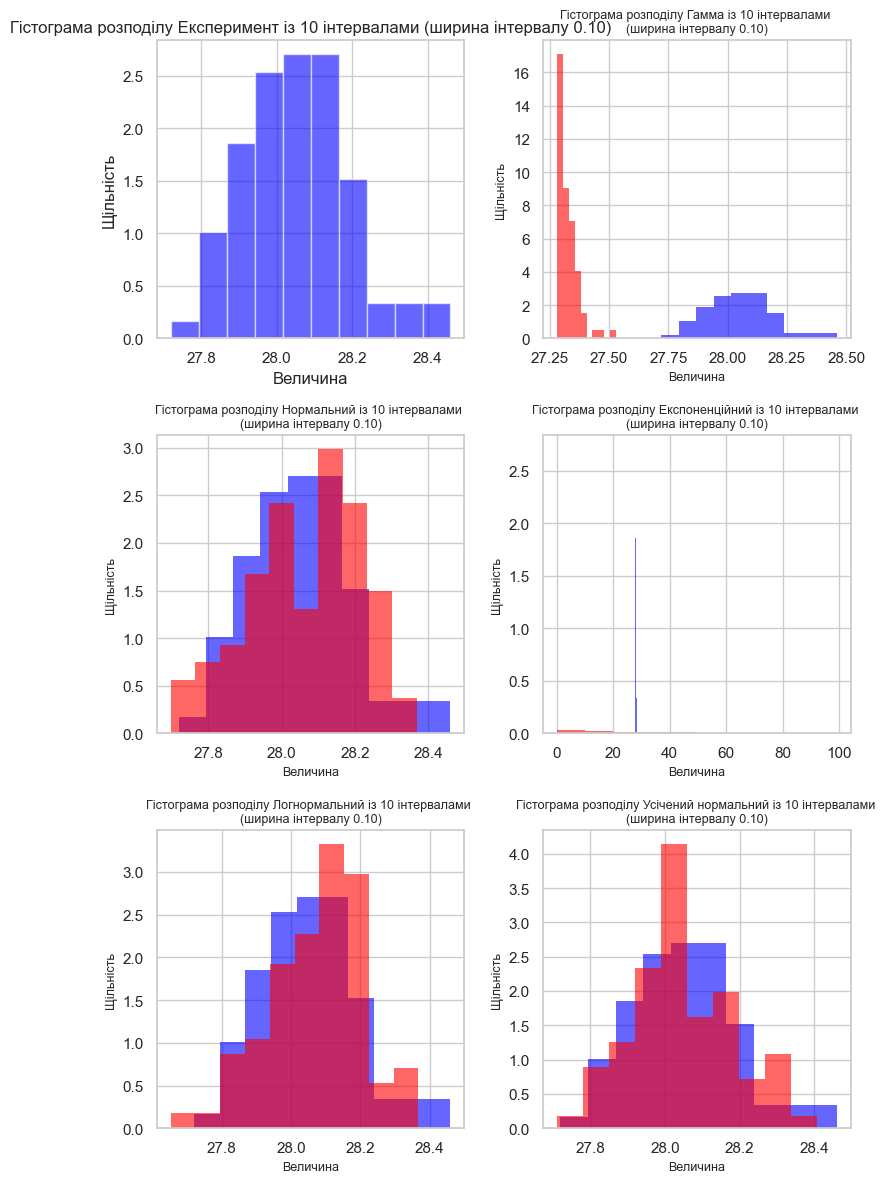

In [13]:
distribution_analysis(df["AvgStoreWait"],10)

Визначення типу розподілу зайнятості малих літаків

Параметри розподілу Ерланга: k=2, loc=2.4485770521498864, scale=0.0004784178504877133
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 720.0000000067638, chi2_treshold: 16.918977604620448
3.464432365046179e-149<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=2.69485, std=0.010755347507170563
Подібність розподілу Нормального: dof: 9, chi2_stat: 9.250000001450648, chi2_treshold: 16.918977604620448
0.4145245216850402>=0.05: не відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=2.69485
Chi-squared test (Exponential): dof: 9, chi2_stat: 720.0000000000001, chi2_treshold: 16.918977604620448
3.4644323766486903e-149<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.003992365958000045, loc=0, scale=2.6948285282057545
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 9.250000001485406, chi2_treshold: 16.918977604620448
0.41452452168192405>=0.05: не відхиляємо гіпотезу
 

Усічений нормальний розподіл:
  loc=2.6949, s

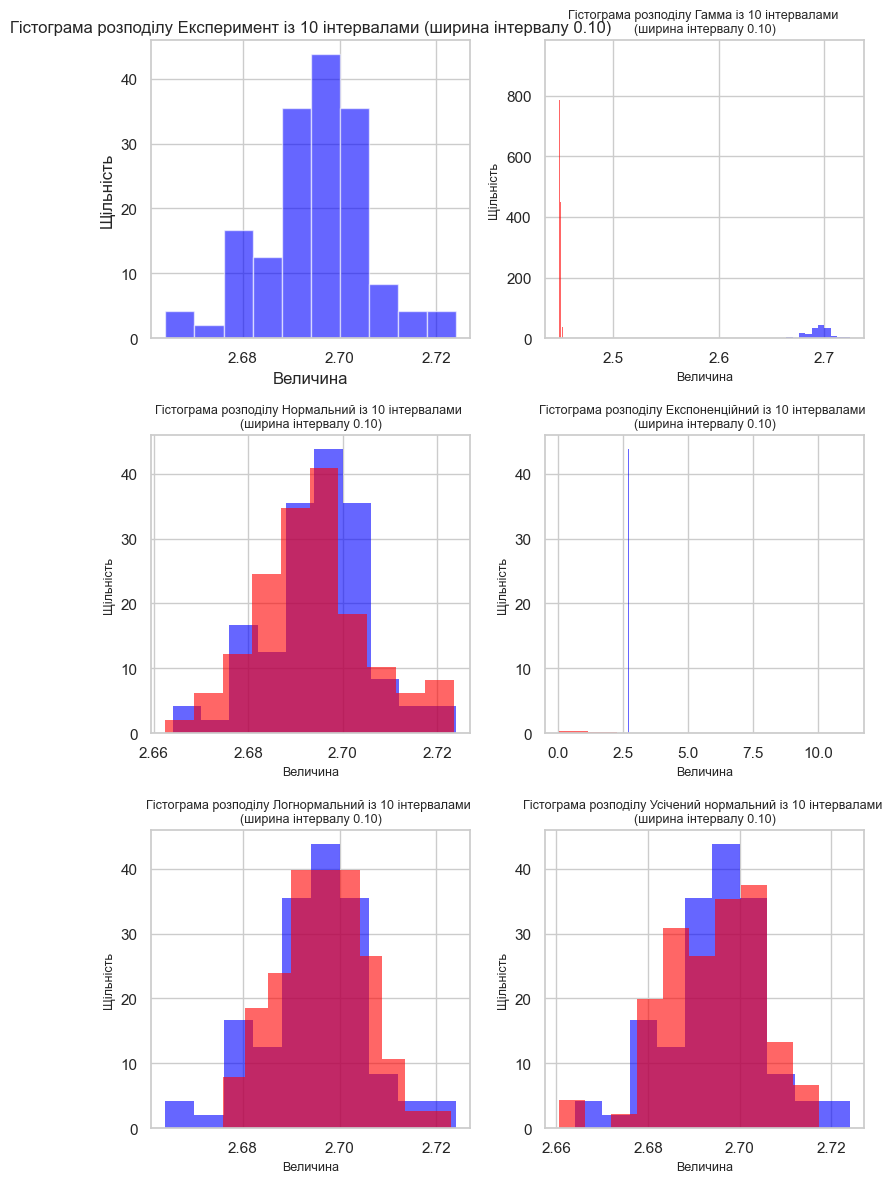

In [14]:
distribution_analysis(df["SmallUtil"],10)

Визначення типу розподілу зайнятості великих літаків

Параметри розподілу Ерланга: k=2, loc=0.7735029447838895, scale=0.0010453612749315886
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 719.9999999980008, chi2_treshold: 16.918977604620448
3.4644323800782933e-149<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=1.0295124999999998, std=0.016065486103756722
Подібність розподілу Нормального: dof: 9, chi2_stat: 15.49999999990822, chi2_treshold: 16.918977604620448
0.07808599256181362>=0.05: не відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=1.0295124999999998
Chi-squared test (Exponential): dof: 9, chi2_stat: 720.0000000000314, chi2_treshold: 16.918977604620448
3.4644323765949737e-149<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.015654643157262463, loc=0, scale=1.0293866284614792
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 13.999999999879513, chi2_treshold: 16.918977604620448
0.12232522804294847>=0.05: не відхиляємо гіпотезу
 

Усічений нормальний 

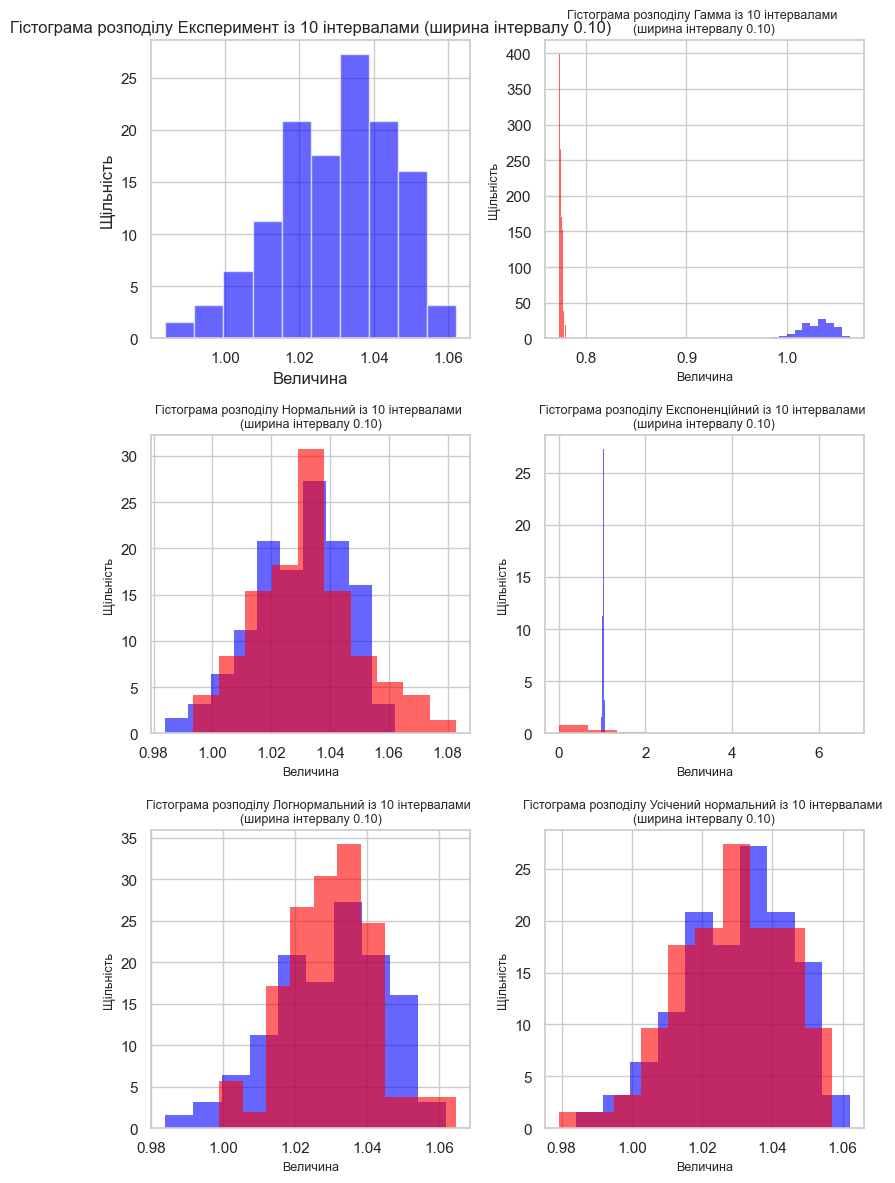

In [15]:
distribution_analysis(df["BigUtil"],10)

# Результати експериментів для дисперсійного аналізу

## Перший експеримент

Порівняння "без часу завантаження" та "1 хвилина на контейнер"

In [16]:
df=pd.read_csv("ExperimentLoadTime.csv")
df.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,160.0,160.0,160.0,160.0,160.00000,160.00000,160.000000,160.000000,160.000000,160.000000
mean,85300.0,3.0,2.0,0.5,0.50000,2148.92800,2.846200,1.511437,4295.593125,161559.625000
std,0.0,0.0,0.0,0.0,0.50157,2132.24686,0.151071,0.484642,4261.977358,8712.375777
min,85300.0,3.0,2.0,0.5,0.00000,27.72000,2.669000,0.989000,55.600000,151700.000000
25%,85300.0,3.0,2.0,0.5,0.00000,28.05750,2.696500,1.028750,56.100000,152875.000000
50%,85300.0,3.0,2.0,0.5,0.50000,1935.51500,2.854500,1.526500,3870.900000,161600.000000
75%,85300.0,3.0,2.0,0.5,1.00000,4238.05500,2.997000,1.994000,8466.425000,170240.000000
max,85300.0,3.0,2.0,0.5,1.00000,4819.74000,2.998000,1.995000,9652.400000,171380.000000


Factor_1 - перша модель, Factor_2 - друга

In [17]:
factor_1=df.iloc[:80]
factor_2=df.iloc[80:]

In [18]:
factor_1.head()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
0,No_Load_Time_Run_0,85300.0,3,2,0.5,0.0,27.96,2.669,1.031,55.6,169220.0
1,No_Load_Time_Run_1,85300.0,3,2,0.5,0.0,27.94,2.687,1.028,55.9,170260.0
2,No_Load_Time_Run_2,85300.0,3,2,0.5,0.0,27.80,2.694,1.036,55.7,170820.0
3,No_Load_Time_Run_3,85300.0,3,2,0.5,0.0,28.02,2.691,1.044,56.1,170200.0
4,No_Load_Time_Run_4,85300.0,3,2,0.5,0.0,27.88,2.685,1.020,55.6,169720.0


In [19]:
factor_2.head()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
80,With_Load_Time_Run_0,85300.0,3,2,0.5,1.0,4236.33,2.996,1.995,8501.7,152660.0
81,With_Load_Time_Run_1,85300.0,3,2,0.5,1.0,4203.95,2.997,1.994,8407.8,153440.0
82,With_Load_Time_Run_2,85300.0,3,2,0.5,1.0,4306.62,2.997,1.994,8610.9,153120.0
83,With_Load_Time_Run_3,85300.0,3,2,0.5,1.0,3966.96,2.997,1.993,7902.1,153340.0
84,With_Load_Time_Run_4,85300.0,3,2,0.5,1.0,4425.46,2.997,1.995,8835.1,152500.0


In [20]:
factor_1.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,80.0,80.0,80.0,80.0,80.0,80.000000,80.000000,80.000000,80.00000,80.000000
mean,85300.0,3.0,2.0,0.5,0.0,28.045875,2.695762,1.028450,56.10125,170229.000000
std,0.0,0.0,0.0,0.0,0.0,0.142506,0.009869,0.016418,0.27901,445.522308
min,85300.0,3.0,2.0,0.5,0.0,27.720000,2.669000,0.989000,55.60000,169120.000000
25%,85300.0,3.0,2.0,0.5,0.0,27.947500,2.688750,1.017750,55.90000,169960.000000
50%,85300.0,3.0,2.0,0.5,0.0,28.055000,2.696000,1.028500,56.10000,170240.000000
75%,85300.0,3.0,2.0,0.5,0.0,28.160000,2.703000,1.039250,56.30000,170560.000000
max,85300.0,3.0,2.0,0.5,0.0,28.350000,2.714000,1.060000,56.80000,171380.000000


In [21]:
factor_2.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,80.0,80.0,80.0,80.0,80.0,80.000000,80.000000,80.000000,80.000000,80.000000
mean,85300.0,3.0,2.0,0.5,1.0,4269.810125,2.996637,1.994425,8535.085000,152890.250000
std,0.0,0.0,0.0,0.0,0.0,200.859906,0.000601,0.000591,396.521025,595.366019
min,85300.0,3.0,2.0,0.5,1.0,3842.680000,2.995000,1.993000,7685.000000,151700.000000
25%,85300.0,3.0,2.0,0.5,1.0,4116.050000,2.996000,1.994000,8230.125000,152475.000000
50%,85300.0,3.0,2.0,0.5,1.0,4239.780000,2.997000,1.994000,8466.750000,152870.000000
75%,85300.0,3.0,2.0,0.5,1.0,4387.685000,2.997000,1.995000,8793.825000,153370.000000
max,85300.0,3.0,2.0,0.5,1.0,4819.740000,2.998000,1.995000,9652.400000,154080.000000


Аналіз Фішера на відмінність

In [ ]:
from scipy import stats



p = 80
f_crit = stats.f.isf(0.05, dfn=1, dfd=2 * (p - 1))

rows = []
for col in ["AvgStoreWait", "SmallUtil", "BigUtil"]:
    y1, y2 = factor_1[col], factor_2[col]
    y1_m, y2_m = y1.mean(), y2.mean()
    y_m = 0.5 * (y1_m + y2_m)
    
    s_fakt = p * ((y1_m - y_m)**2 + (y2_m - y_m)**2)
    d_zalysh = (y1.var(ddof=1) + y2.var(ddof=1)) / 2
    f_calc = s_fakt / d_zalysh
    
    rows.append({
        "Metric": col,
        "Mean_0": round(y1_m, 3),
        "Mean_1": round(y2_m, 3),
        "S_fakt": round(s_fakt, 3),
        "d_zalysh": round(d_zalysh, 4),
        "F_calc": round(f_calc, 2),
        "F_crit": round(f_crit, 3),
        "Significant": f_calc > f_crit
    })

print(pd.DataFrame(rows).to_string(index=False))

      Metric  Mean_0   Mean_1       S_fakt   d_zalysh    F_calc  F_crit  Significant
AvgStoreWait  28.046 4269.810 7.197026e+08 20172.3610  35677.66   3.901         True
   SmallUtil   2.696    2.997 3.621000e+00     0.0000  74080.63   3.901         True
     BigUtil   1.028    1.994 3.732400e+01     0.0001 276562.58   3.901         True


## Другий експеримент

In [23]:
df=pd.read_csv("ExperimentLoadTime_01.csv")
df.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,160.0,160.0,160.0,160.0,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000
mean,83500.0,3.0,2.0,0.5,0.050000,28.294562,2.709062,1.094888,56.575000,166545.000000
std,0.0,0.0,0.0,0.0,0.050157,0.281467,0.016665,0.067744,0.538108,442.064909
min,83500.0,3.0,2.0,0.5,0.000000,27.760000,2.667000,0.994000,55.600000,165440.000000
25%,83500.0,3.0,2.0,0.5,0.000000,28.037500,2.696000,1.027750,56.100000,166180.000000
50%,83500.0,3.0,2.0,0.5,0.050000,28.330000,2.709500,1.099000,56.600000,166520.000000
75%,83500.0,3.0,2.0,0.5,0.100000,28.542500,2.723000,1.159250,57.000000,166900.000000
max,83500.0,3.0,2.0,0.5,0.100000,28.800000,2.745000,1.195000,57.800000,167800.000000


In [24]:
factor_1=df.iloc[:80]
factor_2=df.iloc[80:]

In [25]:
factor_1.head()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
0,No_Load_Time_Run_0,83500.0,3,2,0.5,0.0,28.07,2.705,1.044,56.2,166620.0
1,No_Load_Time_Run_1,83500.0,3,2,0.5,0.0,27.89,2.681,1.047,55.9,167060.0
2,No_Load_Time_Run_2,83500.0,3,2,0.5,0.0,28.14,2.697,1.017,56.5,167260.0
3,No_Load_Time_Run_3,83500.0,3,2,0.5,0.0,28.32,2.687,1.033,56.4,166040.0
4,No_Load_Time_Run_4,83500.0,3,2,0.5,0.0,28.31,2.695,0.995,56.3,165760.0


In [26]:
factor_2.head()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
80,With_Load_Time_Run_0,83500.0,3,2,0.5,0.1,28.46,2.713,1.120,56.8,166040.0
81,With_Load_Time_Run_1,83500.0,3,2,0.5,0.1,28.43,2.717,1.165,57.0,167020.0
82,With_Load_Time_Run_2,83500.0,3,2,0.5,0.1,28.64,2.724,1.157,57.1,165960.0
83,With_Load_Time_Run_3,83500.0,3,2,0.5,0.1,28.41,2.706,1.178,56.8,166560.0
84,With_Load_Time_Run_4,83500.0,3,2,0.5,0.1,28.53,2.729,1.150,57.0,166460.0


In [27]:
factor_1.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,80.0,80.0,80.0,80.0,80.0,80.000000,80.000000,80.000000,80.000000,80.000000
mean,83500.0,3.0,2.0,0.5,0.0,28.054875,2.695288,1.029425,56.112500,166602.250000
std,0.0,0.0,0.0,0.0,0.0,0.156593,0.009850,0.015900,0.280765,410.643136
min,83500.0,3.0,2.0,0.5,0.0,27.760000,2.667000,0.994000,55.600000,165740.000000
25%,83500.0,3.0,2.0,0.5,0.0,27.947500,2.688750,1.019000,55.900000,166320.000000
50%,83500.0,3.0,2.0,0.5,0.0,28.035000,2.696000,1.027500,56.100000,166630.000000
75%,83500.0,3.0,2.0,0.5,0.0,28.152500,2.701000,1.037750,56.300000,166920.000000
max,83500.0,3.0,2.0,0.5,0.0,28.440000,2.716000,1.078000,56.800000,167520.000000


In [28]:
factor_2.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,80.0,80.0,80.0,80.0,8.000000e+01,80.000000,80.000000,80.000000,80.000000,80.000000
mean,83500.0,3.0,2.0,0.5,1.000000e-01,28.534250,2.722837,1.160350,57.037500,166487.750000
std,0.0,0.0,0.0,0.0,1.675841e-16,0.136287,0.008812,0.017451,0.265947,466.958852
min,83500.0,3.0,2.0,0.5,1.000000e-01,28.050000,2.706000,1.120000,56.200000,165440.000000
25%,83500.0,3.0,2.0,0.5,1.000000e-01,28.450000,2.717000,1.147750,56.900000,166150.000000
50%,83500.0,3.0,2.0,0.5,1.000000e-01,28.545000,2.723000,1.159500,57.000000,166460.000000
75%,83500.0,3.0,2.0,0.5,1.000000e-01,28.622500,2.728250,1.171250,57.200000,166885.000000
max,83500.0,3.0,2.0,0.5,1.000000e-01,28.800000,2.745000,1.195000,57.800000,167800.000000


Аналіз Фішера

In [ ]:
from scipy import stats



p = 80
f_crit = stats.f.isf(0.05, dfn=1, dfd=2 * (p - 1))

rows = []
for col in ["AvgStoreWait", "SmallUtil", "BigUtil"]:
    y1, y2 = factor_1[col], factor_2[col]
    y1_m, y2_m = y1.mean(), y2.mean()
    y_m = 0.5 * (y1_m + y2_m)
    
    s_fakt = p * ((y1_m - y_m)**2 + (y2_m - y_m)**2)
    d_zalysh = (y1.var(ddof=1) + y2.var(ddof=1)) / 2
    f_calc = s_fakt / d_zalysh
    
    rows.append({
        "Metric": col,
        "Mean_0": round(y1_m, 3),
        "Mean_1": round(y2_m, 3),
        "S_fakt": round(s_fakt, 3),
        "d_zalysh": round(d_zalysh, 4),
        "F_calc": round(f_calc, 2),
        "F_crit": round(f_crit, 3),
        "Significant": f_calc > f_crit
    })

print(pd.DataFrame(rows).to_string(index=False))

      Metric  Mean_0  Mean_1  S_fakt  d_zalysh  F_calc  F_crit  Significant
AvgStoreWait  28.055  28.534   9.192    0.0215  426.59   3.901         True
   SmallUtil   2.695   2.723   0.030    0.0001  347.62   3.901         True
     BigUtil   1.029   1.160   0.686    0.0003 2460.46   3.901         True


## Третій експеримент: пропозиція вирішення проблеми

In [30]:
df=pd.read_csv("ExperimentLoadTime_ExtraPlane.csv")
df.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,160.0,160.00000,160.0,160.0,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000
mean,83500.0,3.50000,2.0,0.5,0.050000,27.095625,3.118700,0.854525,54.166875,166529.750000
std,0.0,0.50157,0.0,0.0,0.050157,1.008212,0.424902,0.174005,2.013062,418.592956
min,83500.0,3.00000,2.0,0.5,0.000000,25.750000,2.669000,0.641000,51.600000,165400.000000
25%,83500.0,3.00000,2.0,0.5,0.000000,26.077500,2.695750,0.681000,52.175000,166235.000000
50%,83500.0,3.50000,2.0,0.5,0.050000,27.105000,3.109000,0.861000,54.350000,166540.000000
75%,83500.0,4.00000,2.0,0.5,0.100000,28.082500,3.542250,1.027000,56.200000,166785.000000
max,83500.0,4.00000,2.0,0.5,0.100000,28.510000,3.575000,1.061000,56.800000,167520.000000


In [31]:
df.tail()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
155,With_Load_Time_Run_75,83500.0,4,2,0.5,0.1,25.96,3.535,0.711,52.1,166920.0
156,With_Load_Time_Run_76,83500.0,4,2,0.5,0.1,26.02,3.549,0.672,52.1,166720.0
157,With_Load_Time_Run_77,83500.0,4,2,0.5,0.1,25.92,3.540,0.641,51.9,166640.0
158,With_Load_Time_Run_78,83500.0,4,2,0.5,0.1,25.76,3.532,0.702,51.7,167140.0
159,With_Load_Time_Run_79,83500.0,4,2,0.5,0.1,26.10,3.540,0.681,52.2,166820.0


In [32]:
df[80:].describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,80.0,80.0,80.0,80.0,8.000000e+01,80.000000,80.000000,80.000000,80.000000,80.00000
mean,83500.0,4.0,2.0,0.5,1.000000e-01,26.102625,3.542063,0.681850,52.181250,166510.25000
std,0.0,0.0,0.0,0.0,1.675841e-16,0.163364,0.015791,0.017097,0.310611,376.86238
min,83500.0,4.0,2.0,0.5,1.000000e-01,25.750000,3.500000,0.641000,51.600000,165440.00000
25%,83500.0,4.0,2.0,0.5,1.000000e-01,25.990000,3.532750,0.672000,51.975000,166255.00000
50%,83500.0,4.0,2.0,0.5,1.000000e-01,26.075000,3.542500,0.681000,52.150000,166520.00000
75%,83500.0,4.0,2.0,0.5,1.000000e-01,26.202500,3.552000,0.691250,52.400000,166760.00000
max,83500.0,4.0,2.0,0.5,1.000000e-01,26.570000,3.575000,0.730000,53.300000,167240.00000
